# 04 — Full Pipeline Compare

Phase 1, steps 7-8, and **the phase-1 exit gate**.

This notebook sums the modulated bands from `03_carrier_modulation.ipynb`
into a single output, normalizes it, writes/reads a WAV round-trip, then
wraps everything built across `01`-`03` into one function:

```
vocode(audio, sr, n_channels, carrier_type) -> np.ndarray
```

and renders every combination of `n_channels in {4, 8, 16, 22}` x
`carrier_type in {noise, tone}`.

**Validation criterion:** at N=4 the output should sound
clearly garbled/unintelligible; by N=16-22 it should be mostly
intelligible speech. That contrast is the thing to actually listen for
below — code running without errors proves nothing about intelligibility
by itself.

In [18]:
import tempfile
from pathlib import Path

import numpy as np
import soundfile as sf
from scipy import signal
import matplotlib.pyplot as plt
from IPython.display import Audio, display

TARGET_SR = 16000

## Rebuild the pipeline so far (01-03)

Same functions as the previous three notebooks, not re-explained here.

In [19]:
def load_raw(path):
    audio, native_sr = sf.read(path)
    if audio.ndim > 1:
        audio = audio.mean(axis=1)
    return audio.astype(np.float32), native_sr


def resample_to(audio, native_sr, target_sr):
    if native_sr == target_sr:
        return audio
    n_samples = int(len(audio) * target_sr / native_sr)
    return signal.resample(audio, n_samples).astype(np.float32)


def design_filterbank(n_channels, sr, f_min=200, f_max=7000, order=4):
    """Return (sos_list, edges, centers) for N log-spaced Butterworth bandpass filters."""
    edges = np.logspace(np.log10(f_min), np.log10(f_max), n_channels + 1)
    centers = np.sqrt(edges[:-1] * edges[1:])

    nyquist = sr / 2
    sos_list = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        sos = signal.butter(order, [lo / nyquist, hi / nyquist], btype="bandpass", output="sos")
        sos_list.append(sos)

    return sos_list, edges, centers


def split_into_bands(audio, sos_list):
    return [signal.sosfiltfilt(sos, audio) for sos in sos_list]


def envelope_rectify_lowpass(band, sr, cutoff=400, order=4):
    rectified = np.abs(band)
    nyquist = sr / 2
    sos = signal.butter(order, cutoff / nyquist, btype="lowpass", output="sos")
    return signal.sosfiltfilt(sos, rectified)


def extract_envelopes(bands, sr, cutoff=400, order=4):
    return [envelope_rectify_lowpass(b, sr, cutoff, order) for b in bands]


def generate_noise_carrier(sos, length, sr, rng):
    white = rng.standard_normal(length).astype(np.float32)
    return signal.sosfiltfilt(sos, white)


def generate_tone_carrier(center_freq, length, sr):
    t = np.arange(length) / sr
    return np.sin(2 * np.pi * center_freq * t).astype(np.float32)


def generate_carriers(carrier_type, filterbank, centers, length, sr, rng):
    if carrier_type == "noise":
        return [generate_noise_carrier(sos, length, sr, rng) for sos in filterbank]
    elif carrier_type == "tone":
        return [generate_tone_carrier(c, length, sr) for c in centers]
    else:
        raise ValueError(f"unknown carrier_type: {carrier_type!r}")


def modulate_bands(envelopes, carriers):
    return [env * car for env, car in zip(envelopes, carriers)]


speech_raw, speech_native_sr = load_raw("../samples/speech.wav")
music_raw, music_native_sr = load_raw("../samples/music.wav")

speech = resample_to(speech_raw, speech_native_sr, TARGET_SR)
music = resample_to(music_raw, music_native_sr, TARGET_SR)
sr = TARGET_SR

print(f"speech: {len(speech)/sr:.2f}s, music: {len(music)/sr:.2f}s, both @ {sr} Hz")

speech: 2.62s, music: 4.50s, both @ 16000 Hz


## Step 7: mixdown — sum bands, normalize, write/read WAV, listen

Sum the modulated bands, then peak-normalize so the result can't clip
regardless of how many channels or how loud any one band got (more
channels summing in-phase can otherwise push the peak well past +-1).
A small amount of headroom (5%) avoids resampling/encoding artifacts
right at full scale.

In [20]:
def mixdown(modulated_bands, headroom=0.95):
    summed = np.sum(modulated_bands, axis=0)
    peak = np.max(np.abs(summed))
    if peak > 0:
        summed = summed / peak * headroom
    return summed.astype(np.float32)


# one demo pass by hand (N=8, noise) before wrapping it all into vocode()
demo_rng = np.random.default_rng(0)
demo_filterbank, demo_edges, demo_centers = design_filterbank(8, sr)
demo_bands = split_into_bands(speech, demo_filterbank)
demo_envelopes = extract_envelopes(demo_bands, sr)
demo_carriers = generate_carriers("noise", demo_filterbank, demo_centers, len(speech), sr, demo_rng)
demo_modulated = modulate_bands(demo_envelopes, demo_carriers)
demo_output = mixdown(demo_modulated)

print(f"peak before normalize: {np.max(np.abs(np.sum(demo_modulated, axis=0))):.3f}")
print(f"peak after normalize:  {np.max(np.abs(demo_output)):.3f}")

peak before normalize: 0.148
peak after normalize:  0.950


In [21]:
# write/read WAV round-trip to a scratch temp file (not committed to the repo)
with tempfile.TemporaryDirectory() as tmp_dir:
    demo_path = Path(tmp_dir) / "demo_vocoded_n8_noise.wav"
    sf.write(demo_path, demo_output, sr)
    reread, reread_sr = sf.read(demo_path)
    print(f"wrote + reread {demo_path.name}: {len(reread)} samples @ {reread_sr} Hz")

print("speech vocoded, N=8, noise carrier:")
display(Audio(demo_output, rate=sr))

wrote + reread demo_vocoded_n8_noise.wav: 41920 samples @ 16000 Hz
speech vocoded, N=8, noise carrier:


## Step 8: wrap it all as `vocode()`

This is the function Phase 2 gets translated from — same signature in
spirit, same five-stage pipeline (filterbank -> envelopes -> carriers ->
modulate -> mixdown).

In [22]:
def vocode(audio, sr, n_channels, carrier_type, f_min=200, f_max=7000,
           filter_order=4, env_cutoff=400, rng=None):
    """Channel-vocode `audio` into `n_channels` log-spaced bands using
    either a `noise` or `tone` carrier per band. Returns a normalized,
    clip-safe float32 array at the same sample rate as the input."""
    if rng is None:
        rng = np.random.default_rng(0)

    filterbank, edges, centers = design_filterbank(n_channels, sr, f_min, f_max, filter_order)
    bands = split_into_bands(audio, filterbank)
    envelopes = extract_envelopes(bands, sr, env_cutoff, filter_order)
    carriers = generate_carriers(carrier_type, filterbank, centers, len(audio), sr, rng)
    modulated = modulate_bands(envelopes, carriers)
    return mixdown(modulated)


# sanity check: vocode() should reproduce the hand-built demo above
check = vocode(speech, sr, 8, "noise", rng=np.random.default_rng(0))
print(f"vocode() matches hand-built demo: {np.allclose(check, demo_output)}")

vocode() matches hand-built demo: True


## The exit gate: listen across every N x carrier_type combination

**This is the part that actually matters** — everything above just proves
the code runs. Listen to each clip below and confirm: N=4 should sound
clearly garbled/unintelligible; by N=16-22 it should be mostly
intelligible speech. If that contrast doesn't show up, the pipeline needs
fixing (check filter spacing first, then envelope cutoff) before any
Swift work starts.

In [23]:
N_VALUES = [4, 8, 16, 22]
CARRIER_TYPES = ["noise", "tone"]

for carrier_type in CARRIER_TYPES:
    for n in N_VALUES:
        out = vocode(speech, sr, n, carrier_type, rng=np.random.default_rng(0))
        print(f"speech — N={n}, carrier={carrier_type}:")
        display(Audio(out, rate=sr))

speech — N=4, carrier=noise:


speech — N=8, carrier=noise:


speech — N=16, carrier=noise:


speech — N=22, carrier=noise:


speech — N=4, carrier=tone:


speech — N=8, carrier=tone:


speech — N=16, carrier=tone:


speech — N=22, carrier=tone:


## Visual corroboration: spectrograms at the extremes

N=4 should show four coarse, blocky energy bands; N=22 should show much
finer frequency detail closer to the original speech's spectrogram.

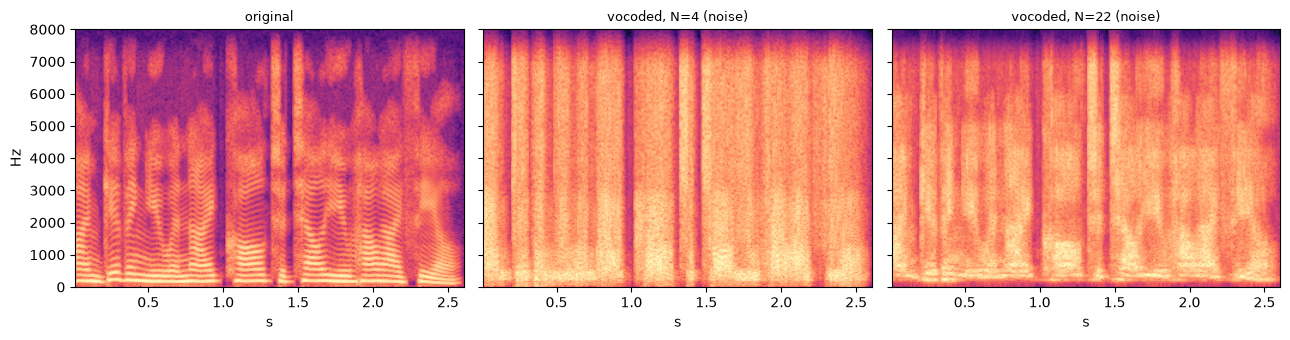

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)

for ax, (label, sig) in zip(axes, [
    ("original", speech),
    ("vocoded, N=4 (noise)", vocode(speech, sr, 4, "noise", rng=np.random.default_rng(0))),
    ("vocoded, N=22 (noise)", vocode(speech, sr, 22, "noise", rng=np.random.default_rng(0))),
]):
    ax.specgram(sig, Fs=sr, NFFT=512, noverlap=384, cmap="magma")
    ax.set_title(label, fontsize=9)
    ax.set_xlabel("s")

axes[0].set_ylabel("Hz")
plt.tight_layout()
plt.show()

## Quick check: music through the same extremes

Music isn't the validation criterion (that's speech intelligibility),
but it's worth a quick listen at both ends too, since the app supports
music clips as a runtime option.

In [25]:
for carrier_type in CARRIER_TYPES:
    for n in (4, 22):
        out = vocode(music, sr, n, carrier_type, rng=np.random.default_rng(0))
        print(f"music — N={n}, carrier={carrier_type}:")
        display(Audio(out, rate=sr))

music — N=4, carrier=noise:


music — N=22, carrier=noise:


music — N=4, carrier=tone:


music — N=22, carrier=tone:
